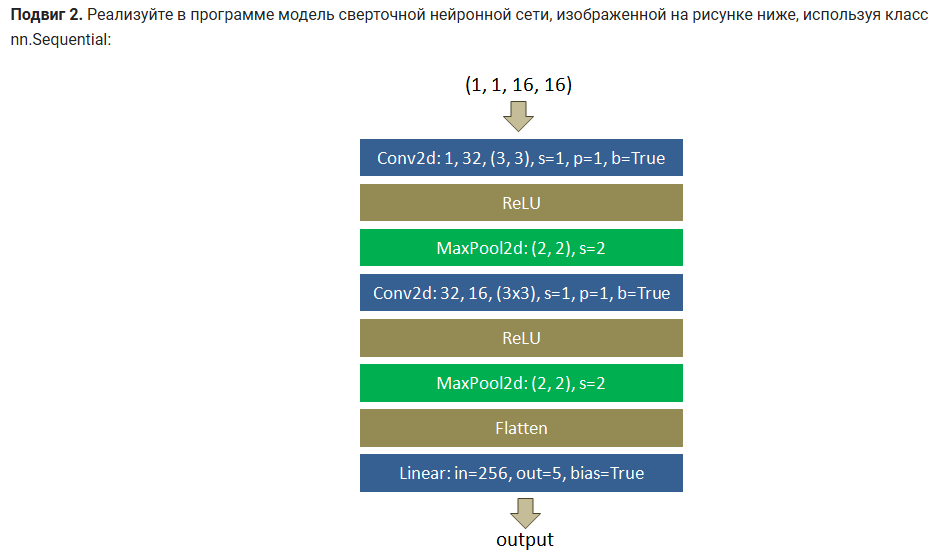

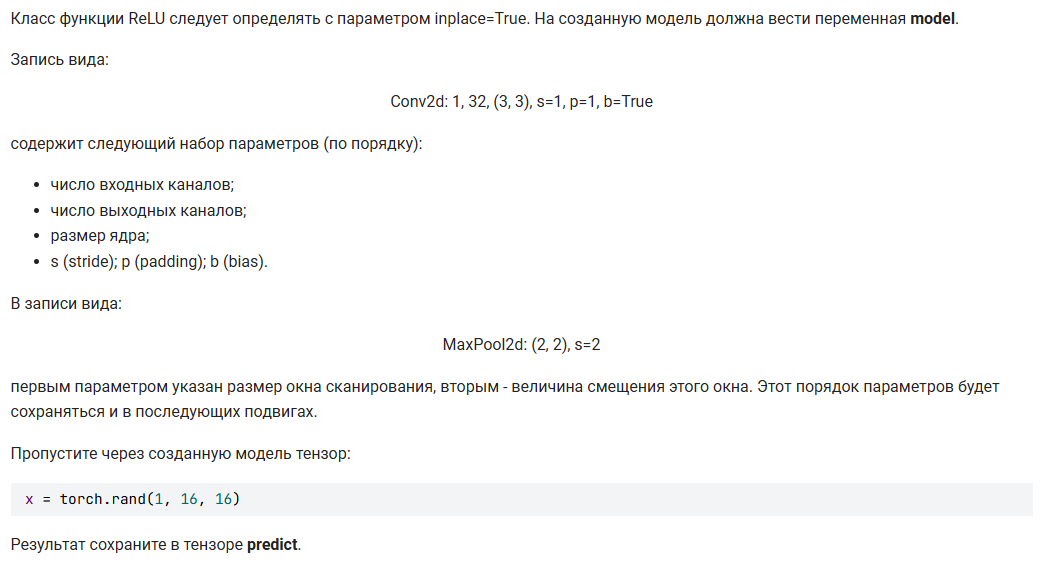

In [8]:
import torch
import torch.nn as nn

x = torch.rand(1, 16, 16) # тензор x в программе не менять

model = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),
    
        nn.Conv2d(in_channels=32, out_channels=16, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),

        nn.Flatten(),
        nn.Linear(in_features=256, out_features=5, bias=True) 
)

predict = model(x.unsqueeze(0))
predict


tensor([[0.1416, 0.3150, 0.2135, 0.0315, 0.2518]], grad_fn=<AddmmBackward0>)

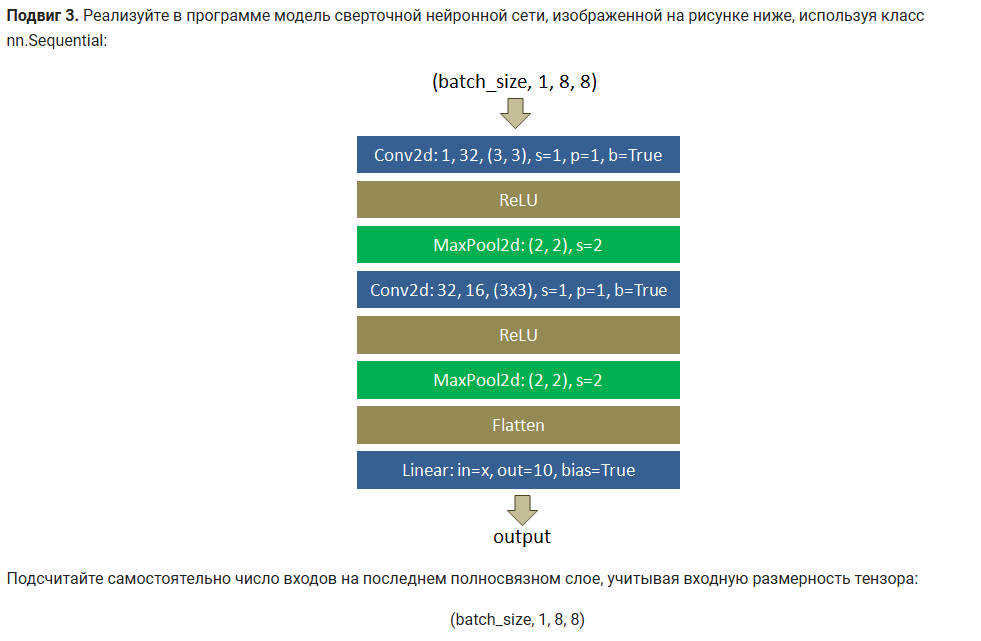

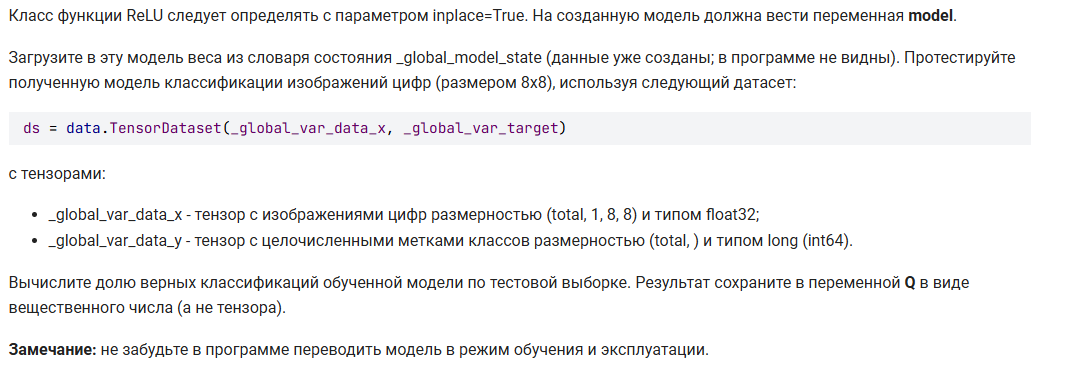

In [28]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

from sklearn.datasets import load_digits
import torch

digits = load_digits()

# Признаки и целевые значения
_global_var_data_x = torch.tensor(digits.data, dtype=torch.float32).view(-1, 1, 8, 8)
_global_var_target = torch.tensor(digits.target, dtype=torch.int64)

ds = data.TensorDataset(_global_var_data_x, _global_var_target)

# здесь продолжайте программу
model = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=32, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),
    
        nn.Conv2d(in_channels=32, out_channels=16, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),

        nn.Flatten(),
        nn.Linear(in_features=64, out_features=10, bias=True) 
)

torch.save(model.state_dict(), 'my_model.tar')
_global_model_state = torch.load('my_model.tar', weights_only=False)

model.load_state_dict(_global_model_state)

predict = model(_global_var_data_x)
predict = torch.sigmoid(predict)
predict = torch.argmax(predict, dim=1)
Q = torch.mean((predict==_global_var_target).float()).item()
Q




0.053978852927684784

In [27]:
_global_var_target

tensor([0, 1, 2,  ..., 8, 9, 8])

In [22]:
_global_var_target

tensor([0, 1, 2,  ..., 8, 9, 8])

In [24]:
model

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU(inplace=True)
  (5): MaxPool2d(kernel_size=(2, 2), stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=64, out_features=10, bias=True)
)

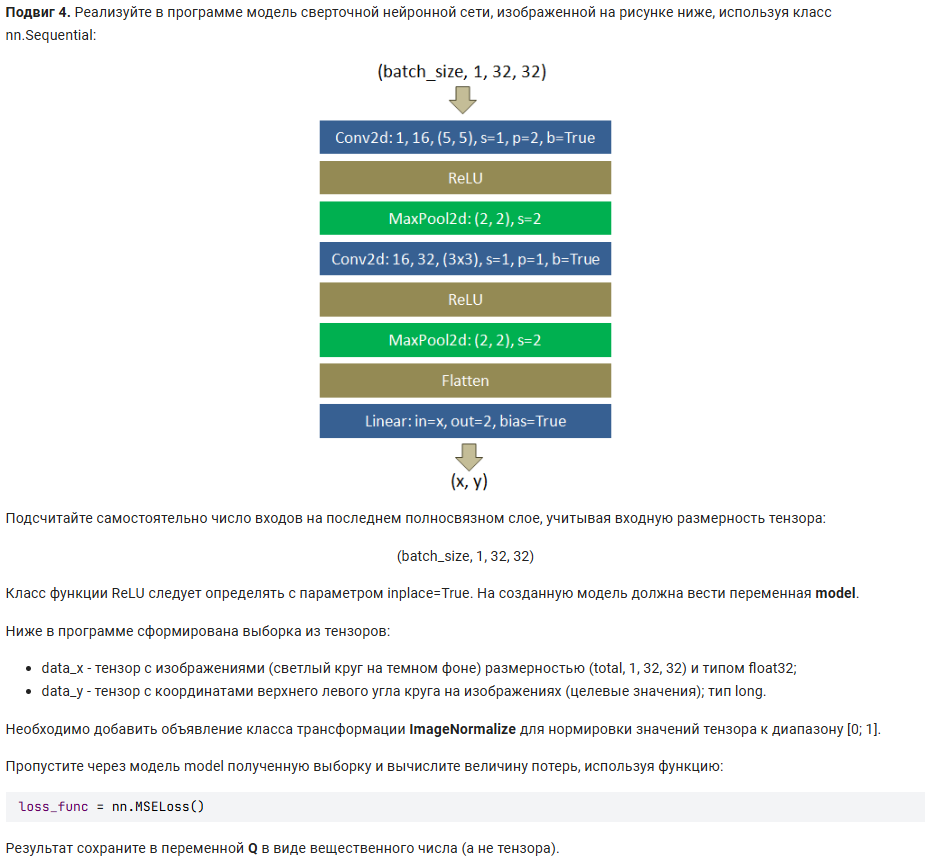

In [79]:
import torch
import torch.nn as nn

# здесь объявляйте класс ImageNormalize
class ImageNormalize(nn.Module):
    def forward(self, item):
        min_value = item.min()
        max_value = item.max()
        return (item-min_value) / (max_value-min_value)


# генерация образов выборки
total = 100 # размер выборки
H, W = 32, 32 # размер изображений
circle = torch.tensor([[0, 0, 0, 255, 255, 255, 255, 0, 0, 0],
                       [0, 255, 255, 255, 255, 255, 255, 255, 255, 0],
                       [0, 255, 255, 255, 255, 255, 255, 255, 255, 0],
                       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
                       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
                       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
                       [255, 255, 255, 255, 255, 255, 255, 255, 255, 255],
                       [0, 255, 255, 255, 255, 255, 255, 255, 255, 0],
                       [0, 255, 255, 255, 255, 255, 255, 255, 255, 0],
                       [0, 0, 0, 255, 255, 255, 255, 0, 0, 0]], dtype=torch.float32)
Hc, Wc = circle.size()


def _generate_img(_H, _W, _Hc, _Wc, _x, _y, _circle, _tr): # вспомогательная функция
    img = torch.rand(_H, _W) * 20
    img[_x:_x+_Hc, _y:_y+Wc] = _circle
    return _tr(img.view(1, 1, _H, _W))


transform = ImageNormalize() # создайте объект класса ImageNormalize
data_y = torch.tensor([(torch.randint(0, H-Hc, (1, )), torch.randint(0, W-Wc, (1, ))) for _ in range(total)])
data_x = torch.cat([_generate_img(H, W, Hc, Wc, _x[0], _x[1], circle, transform) for _x in data_y], dim=0)

torch.manual_seed(1)
# здесь создавайте модель (обязательно сразу после команды torch.manual_seed(1))
model = nn.Sequential(
        nn.Conv2d(in_channels=1, out_channels=16, kernel_size =(5, 5), stride=1, padding=2, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),
    
        nn.Conv2d(in_channels=16, out_channels=32, kernel_size =(3, 3), stride=1, padding=1, bias=True),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=(2, 2), stride=2),

        nn.Flatten(),
        nn.Linear(in_features=2048, out_features=2, bias=True) 
)

loss_func = nn.MSELoss()
# пропустите через модель выборку data_x
model.eval()
predict = model(data_x)
Q = loss_func(predict, data_y.float()).item() # вычислите величину потерь, используя функцию loss_func = nn.MSELoss()
Q

144.92755126953125

In [74]:
data_y.dtype

torch.int64

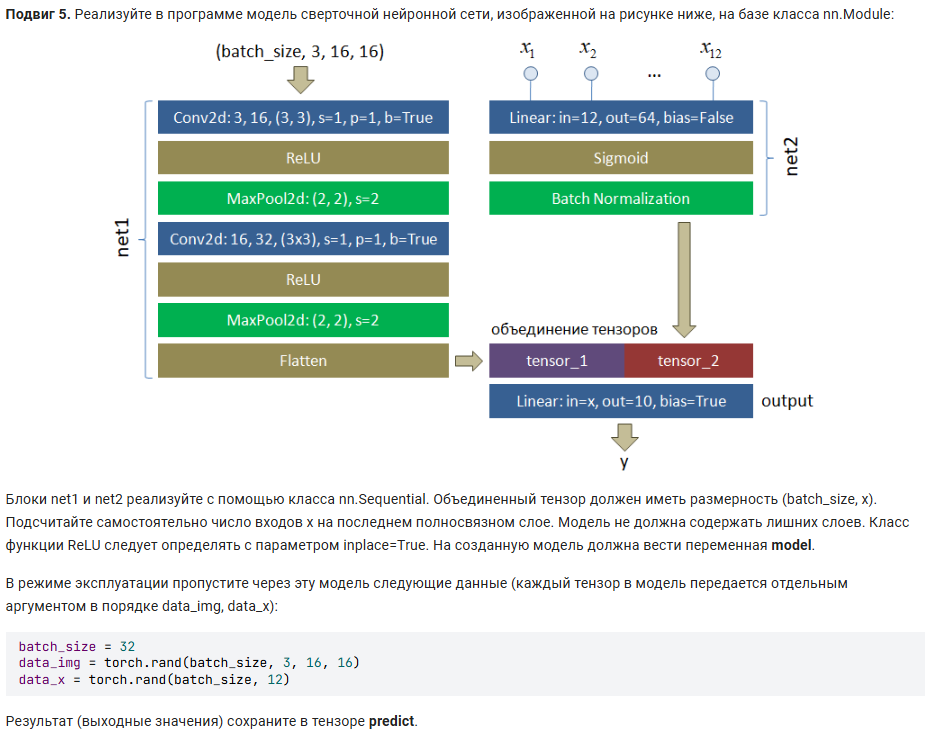

In [98]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели

class MyNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.net1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size =(3, 3), stride=1, padding=1, bias=True),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size =(3, 3), stride=1, padding=1, bias=True),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            nn.Flatten())
        
        self.net2 = nn.Sequential(
            nn.Linear(in_features=12, out_features=64, bias=False),
            nn.Sigmoid(),
            nn.BatchNorm1d(64)
            )
        
        self.common_linear = nn.Linear(512+64, 10, bias=True)
        
    def forward(self, img, x):
        res1 = self.net1(img)
        res2 = self.net2(x)
        res = torch.cat([res1, res2], dim=1)
        return self.common_linear(res)

# тензоры data_img, data_x в программе не менять
batch_size = 32
data_img = torch.rand(batch_size, 3, 16, 16)
data_x = torch.rand(batch_size, 12)

# здесь продолжайте программу
model = MyNet()
model.eval()
predict = model(data_img, data_x)
predict

tensor([[-0.0386, -0.1582,  0.1631,  0.2779,  0.0656,  0.1573, -0.2306, -0.0986,
         -0.2006, -0.0777],
        [-0.0173, -0.1844,  0.1250,  0.2915,  0.0523,  0.1511, -0.2273, -0.0648,
         -0.1785, -0.0825],
        [-0.0409, -0.1887,  0.1574,  0.2927,  0.0457,  0.1584, -0.2191, -0.0254,
         -0.1942, -0.1031],
        [-0.0296, -0.1890,  0.1115,  0.2783,  0.0164,  0.1909, -0.2380, -0.0483,
         -0.1889, -0.0799],
        [-0.0610, -0.1467,  0.1402,  0.2802,  0.0448,  0.1807, -0.2223, -0.0657,
         -0.1625, -0.0744],
        [-0.0388, -0.1646,  0.1385,  0.2728,  0.0444,  0.1822, -0.2143, -0.0846,
         -0.1966, -0.0848],
        [-0.0261, -0.1620,  0.1156,  0.2735,  0.0500,  0.1465, -0.2330, -0.0419,
         -0.1522, -0.0450],
        [-0.0418, -0.1344,  0.1255,  0.2777,  0.0435,  0.1785, -0.2152, -0.0917,
         -0.1765, -0.1066],
        [-0.0366, -0.1578,  0.1436,  0.2580,  0.0458,  0.1749, -0.2157, -0.0444,
         -0.1890, -0.0738],
        [-0.0571, -

In [82]:
nn.Sigmoid()

Sigmoid()

In [88]:
model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size =(3, 3), stride=1, padding=1, bias=True),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
        
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size =(3, 3), stride=1, padding=1, bias=True),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
    
            nn.Flatten(),
            )

data_img = torch.rand(2, 3, 16, 16)

model(data_img).shape

torch.Size([2, 512])

In [86]:
data_x.shape

torch.Size([32, 12])